In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")


Libraries loaded successfully!


In [2]:

df = pd.read_csv("../data/life_expectancy_raw.csv")

print("CSV file successfully loaded!")
print("Rows and columns:", df.shape)

df.head()


CSV file successfully loaded!
Rows and columns: (2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:

# 1. Dataset ka size
print("Dataset shape:", df.shape)

# 2. Sabhi column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Data types aur non-missing values
print("\nDataset information:")
df.info()

# 4. Missing values per column
print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (2938, 22)

Column names:
['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure', 'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population', ' thinness  1-19 years', ' thinness 5-9 years', 'Income composition of resources', 'Schooling']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    29

In [4]:

# Missing values ki count
missing = df.isnull().sum()

# Sirf wahi columns dikhao jahan missing values hain
missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df) * 100).round(2)
})

missing_summary = missing_summary[missing_summary["Missing Values"] > 0]

print("Missing values summary:")
display(missing_summary.sort_values("Missing Percentage", ascending=False))

# Duplicate rows check karo
print("Duplicate rows:", df.duplicated().sum())

# Numeric columns ka statistical summary
display(df.describe().round(2))


Missing values summary:


,Missing Values,Missing Percentage
Population,652,22.19
Hepatitis B,553,18.82
GDP,448,15.25
Total expenditure,226,7.69
Alcohol,194,6.60
Income composition of resources,167,5.68
Schooling,163,5.55
thinness 5-9 years,34,1.16
thinness 1-19 years,34,1.16
BMI,34,1.16


Duplicate rows: 0


,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.00,2928.00,2928.00,2938.00,2744.00,2938.00,2385.00,2938.00,2904.00,2938.00,2919.00,2712.00,2919.00,2938.00,2490.00,2.286000e+03,2904.00,2904.00,2771.00,2775.00
mean,2007.52,69.22,164.80,30.30,4.60,738.25,80.94,2419.59,38.32,42.04,82.55,5.94,82.32,1.74,7483.16,1.275338e+07,4.84,4.87,0.63,11.99
std,4.61,9.52,124.29,117.93,4.05,1987.91,25.07,11467.27,20.04,160.45,23.43,2.50,23.72,5.08,14270.17,6.101210e+07,4.42,4.51,0.21,3.36
min,2000.00,36.30,1.00,0.00,0.01,0.00,1.00,0.00,1.00,0.00,3.00,0.37,2.00,0.10,1.68,3.400000e+01,0.10,0.10,0.00,0.00
25%,2004.00,63.10,74.00,0.00,0.88,4.69,77.00,0.00,19.30,0.00,78.00,4.26,78.00,0.10,463.94,1.957932e+05,1.60,1.50,0.49,10.10
50%,2008.00,72.10,144.00,3.00,3.76,64.91,92.00,17.00,43.50,4.00,93.00,5.76,93.00,0.10,1766.95,1.386542e+06,3.30,3.30,0.68,12.30
75%,2012.00,75.70,228.00,22.00,7.70,441.53,97.00,360.25,56.20,28.00,97.00,7.49,97.00,0.80,5910.81,7.420359e+06,7.20,7.20,0.78,14.30
max,2015.00,89.00,723.00,1800.00,17.87,19479.91,99.00,212183.00,87.30,2500.00,99.00,17.60,99.00,50.60,119172.74,1.293859e+09,27.70,28.60,0.95,20.70


In [5]:

# Original data ko safe rakhte hue copy banao
df_clean = df.copy()

# Column names ke aage-peeche ke extra spaces hatao
df_clean.columns = df_clean.columns.str.strip()

# Column names mein extra spaces ko ek space mein badlo
df_clean.columns = df_clean.columns.str.replace(r"\s+", " ", regex=True)

print("Column names cleaned successfully!")
print(df_clean.columns.tolist())


Column names cleaned successfully!
['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness 1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']


In [6]:

# Cleaning se pehle duplicate rows
duplicates_before = df_clean.duplicated().sum()
print("Duplicate rows before cleaning:", duplicates_before)

# Exact duplicate rows remove karo
df_clean = df_clean.drop_duplicates().copy()

# Cleaning ke baad
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())
print("Cleaned dataset shape:", df_clean.shape)


Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0
Cleaned dataset shape: (2938, 22)


In [7]:

df_clean.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [8]:

# Har column mein missing values ki count
missing_count = df_clean.isnull().sum()

# Sirf missing values wale columns
missing_count = missing_count[missing_count > 0]

print("Missing values before handling:")
display(missing_count.sort_values(ascending=False))


Missing values before handling:


Population                         652
Hepatitis B                        553
GDP                                448
Total expenditure                  226
Alcohol                            194
Income composition of resources    167
Schooling                          163
thinness 5-9 years                  34
thinness 1-19 years                 34
BMI                                 34
Polio                               19
Diphtheria                          19
Life expectancy                     10
Adult Mortality                     10
dtype: int64

In [9]:

missing_percent = (
    df_clean.isnull().sum() / len(df_clean) * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": missing_percent
})

display(
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing Percentage", ascending=False)
)


,Missing Count,Missing Percentage
Population,652,22.19
Hepatitis B,553,18.82
GDP,448,15.25
Total expenditure,226,7.69
Alcohol,194,6.60
Income composition of resources,167,5.68
Schooling,163,5.55
thinness 5-9 years,34,1.16
thinness 1-19 years,34,1.16
BMI,34,1.16


In [10]:

# Missing values ka percentage
missing_percent = (df_clean.isnull().sum() / len(df_clean) * 100).round(2)

# Report banao
missing_report = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": missing_percent
})

display(
    missing_report[missing_report["Missing Count"] > 0]
    .sort_values("Missing Percentage", ascending=False)
)


,Missing Count,Missing Percentage
Population,652,22.19
Hepatitis B,553,18.82
GDP,448,15.25
Total expenditure,226,7.69
Alcohol,194,6.60
Income composition of resources,167,5.68
Schooling,163,5.55
thinness 5-9 years,34,1.16
thinness 1-19 years,34,1.16
BMI,34,1.16


In [11]:

# Numeric columns mein median se missing values fill karo
numeric_cols = df_clean.select_dtypes(include="number").columns

for col in numeric_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Categorical columns mein mode se missing values fill karo
categorical_cols = df_clean.select_dtypes(include=["object", "category"]).columns

for col in categorical_cols:
    if df_clean[col].isnull().any():
        mode_values = df_clean[col].mode()
        if not mode_values.empty:
            df_clean[col] = df_clean[col].fillna(mode_values[0])

print("Missing values remaining:", df_clean.isnull().sum().sum())


Missing values remaining: 0


In [12]:

from pathlib import Path

# Cleaned data save karne ke liye folder
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Cleaned CSV file save karo
output_file = output_dir / "cleaned_life_expectancy.csv"
df_clean.to_csv(output_file, index=False)

print("Cleaned CSV saved successfully!")
print("File path:", output_file)
print("Final dataset shape:", df_clean.shape)


Cleaned CSV saved successfully!
File path: ..\data\processed\cleaned_life_expectancy.csv
Final dataset shape: (2938, 22)


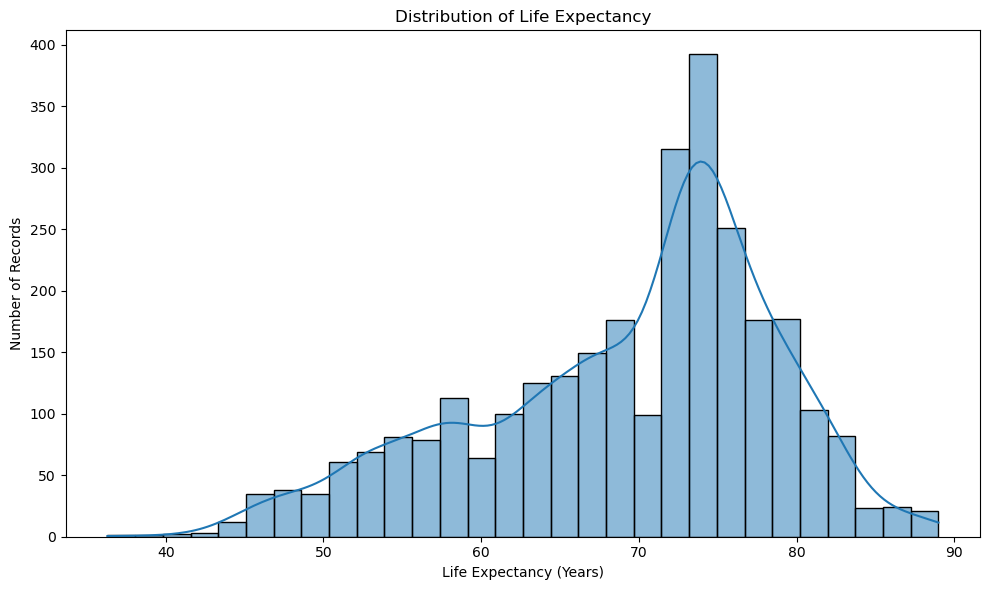

In [13]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x="Life expectancy",
    bins=30,
    kde=True
)

plt.title("Distribution of Life Expectancy")
plt.xlabel("Life Expectancy (Years)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


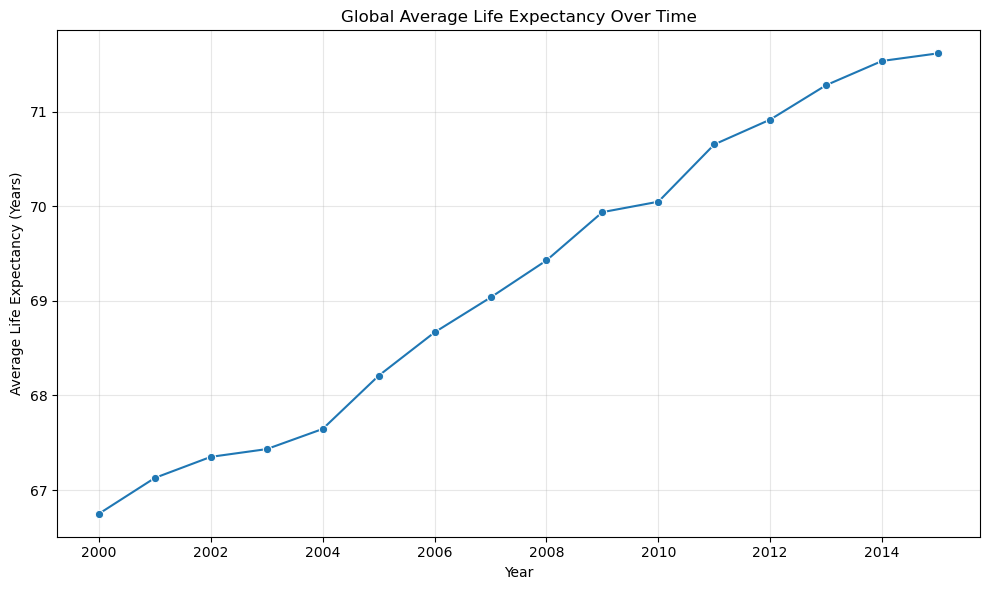

In [14]:

# Har year ki average life expectancy calculate karo
yearly_avg = (
    df_clean.groupby("Year")["Life expectancy"]
    .mean()
    .reset_index()
    .sort_values("Year")
)

# Line graph banao
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=yearly_avg,
    x="Year",
    y="Life expectancy",
    marker="o"
)

plt.title("Global Average Life Expectancy Over Time")
plt.xlabel("Year")
plt.ylabel("Average Life Expectancy (Years)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


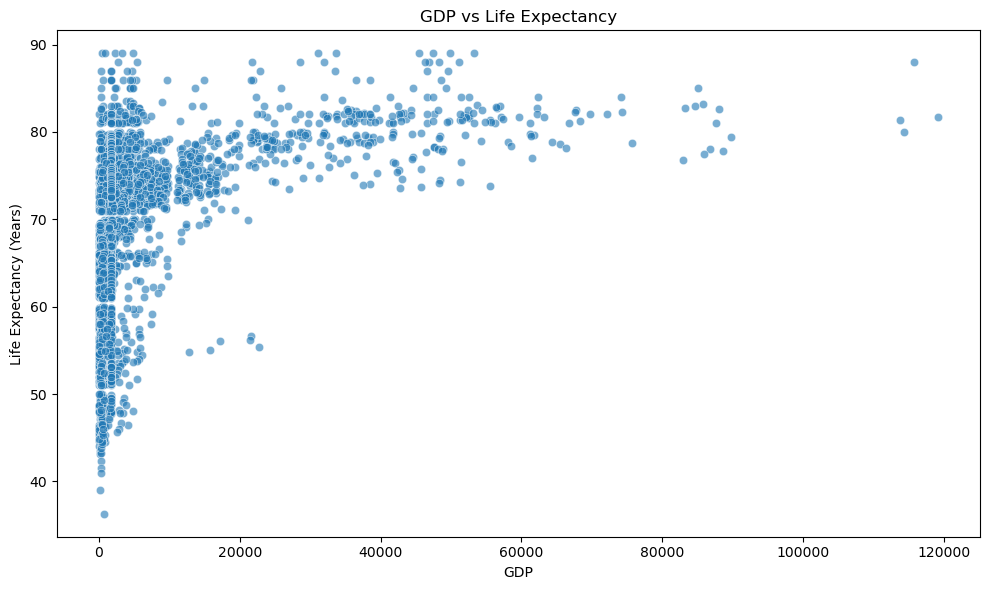

In [15]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="GDP",
    y="Life expectancy",
    alpha=0.6
)

plt.title("GDP vs Life Expectancy")
plt.xlabel("GDP")
plt.ylabel("Life Expectancy (Years)")
plt.tight_layout()
plt.show()


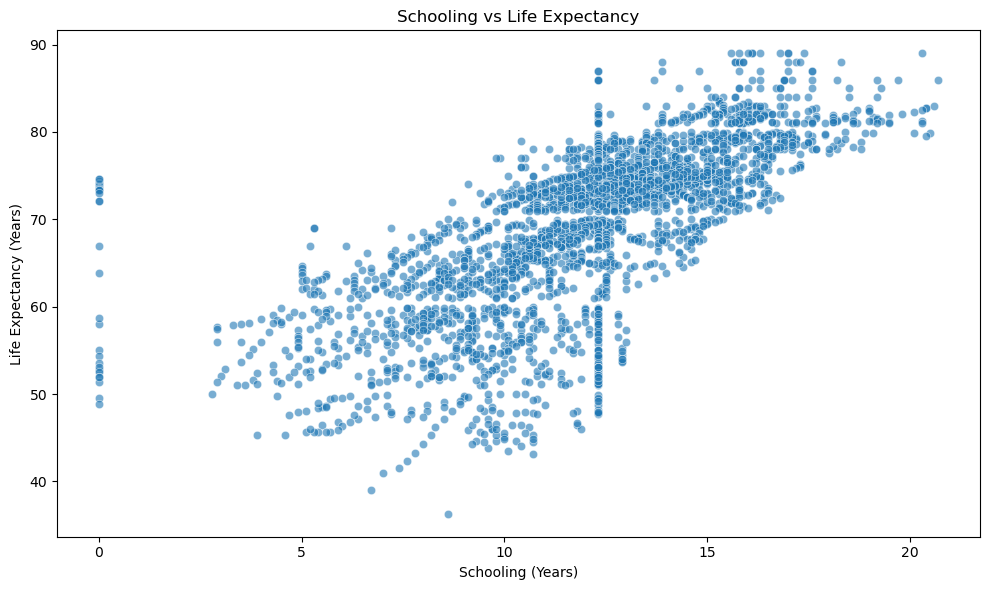

In [16]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="Schooling",
    y="Life expectancy",
    alpha=0.6
)

plt.title("Schooling vs Life Expectancy")
plt.xlabel("Schooling (Years)")
plt.ylabel("Life Expectancy (Years)")
plt.tight_layout()
plt.show()


       Status  Life expectancy
0   Developed        79.197852
1  Developing        67.132028


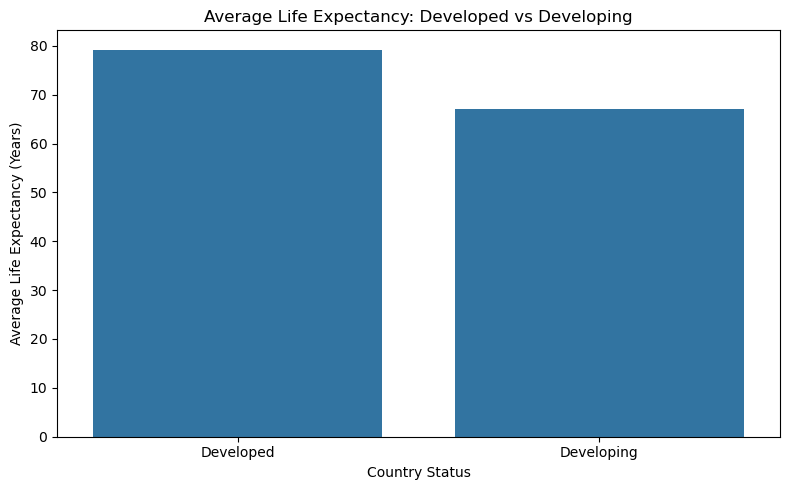

In [17]:

# Status ke hisaab se average life expectancy
status_avg = (
    df_clean.groupby("Status")["Life expectancy"]
    .mean()
    .reset_index()
)

print(status_avg)

# Bar graph
plt.figure(figsize=(8, 5))

sns.barplot(
    data=status_avg,
    x="Status",
    y="Life expectancy"
)

plt.title("Average Life Expectancy: Developed vs Developing")
plt.xlabel("Country Status")
plt.ylabel("Average Life Expectancy (Years)")
plt.tight_layout()
plt.show()


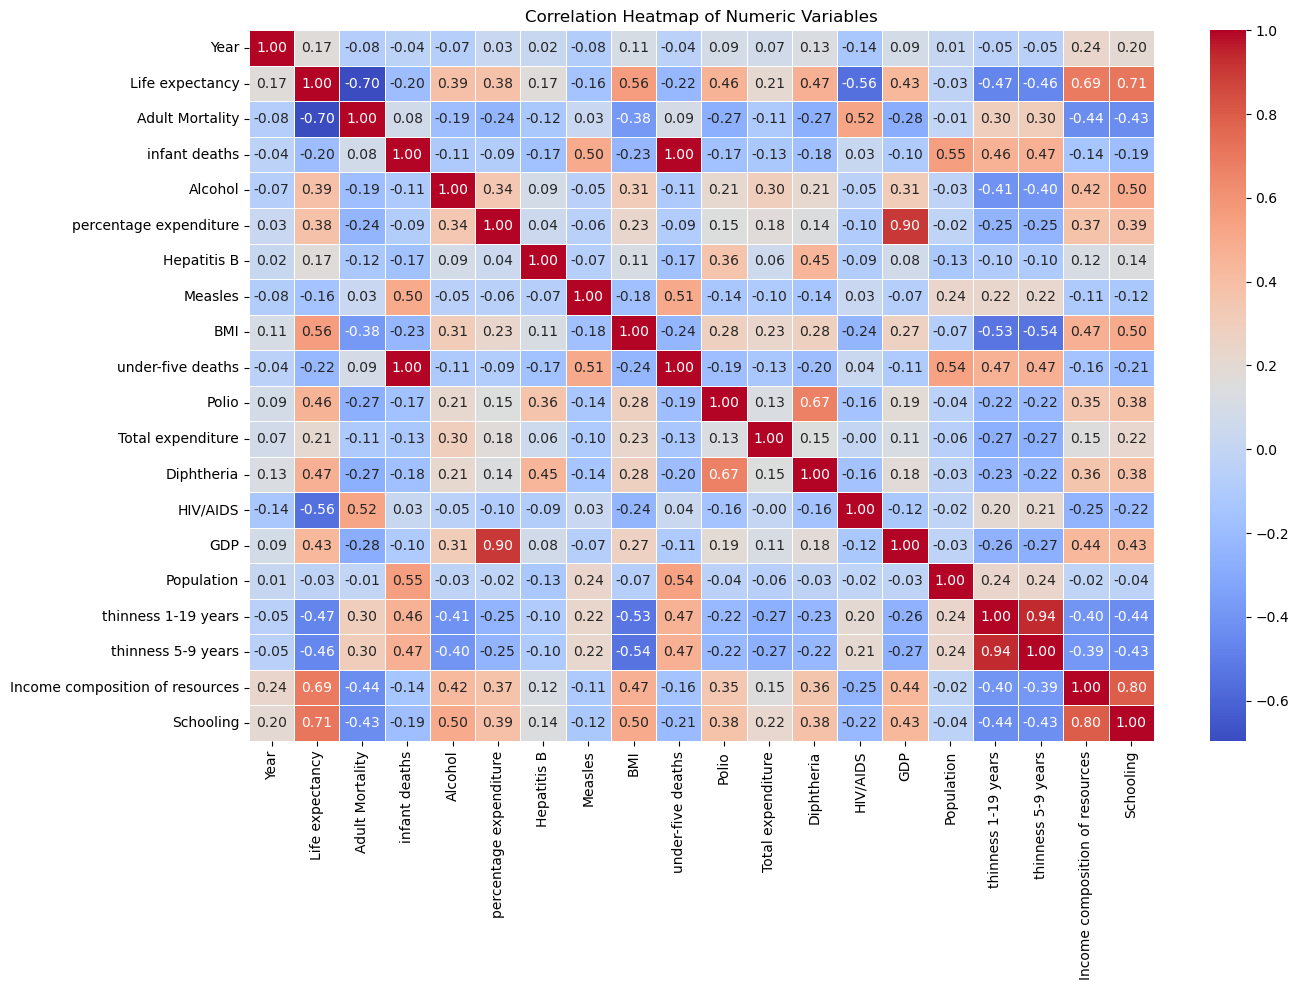

In [18]:

# Numerical columns select karo
numeric_df = df_clean.select_dtypes(include="number")

# Correlation calculate karo
correlation = numeric_df.corr()

# Heatmap banao
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()
